# Christmas and New Year presence
Yogyakarta · JogjaPulse · Role 4

Open this notebook in Google Colab and choose **Runtime → Run all**. The notebook includes the upstream summary tables needed for this figure. The final cell displays the result and writes a PNG to the current directory.

In [1]:
from pathlib import Path
from io import BytesIO
import base64, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

PRIMARY_PERIODS = ['2021_Dec','2022_Jan','2022_Feb_P1','2022_Feb_P2']
COLORS = {
    "education_campus": "#0072B2",
    "healthcare_hospital": "#CC6677",
    "commercial_mall": "#AA4499",
    "traditional_market": "#B57700",
    "tourism_site": "#00896B",
    "transit_hub": "#674EA7",
    "baseline_candidate": "#647482",
    "mixed_use": "#503E35",
    "no_selected_facility": "#CBD2D4",
}
LABELS = {
    "education_campus": "Campuses",
    "healthcare_hospital": "Hospitals",
    "commercial_mall": "Malls",
    "traditional_market": "Markets",
    "tourism_site": "Tourism",
    "transit_hub": "Transit",
    "baseline_candidate": "Baseline candidates",
    "mixed_use": "Mixed use",
    "no_selected_facility": "No selected facility mapped",
}
MISSING = "#d9dfe2"
BREAK = pd.Timestamp("2022-01-01")


PERIOD_NAMES = {
    "2021_Dec": "December 2021",
    "2022_Jan": "January 2022",
    "2022_Feb_P1": "February 1–15",
    "2022_Feb_P2": "February 16–28",
    "2022_Mar_Apr_Exploratory": "March–April (exploratory)",
}




## Source data
Snapshot of `data/gold/event_window.parquet`, `data/silver/daily_coverage_summary.parquet` generated by the merged project pipeline. Expand the folded cell to inspect the embedded data.

In [2]:
# @title Load the embedded summary tables
encoded = {'gold/event_window': 'eNqtmdtu2zgQhu8X2HfIAygGZ4bDQ68Xe7HXey8oNrcR6hMku92+/f6UU7eFZXkHTSJSDmB/Gg9/zoEZu91x2+8/tscy9IdNs+lOpVlj+ngYvjbrst2OzXp7Hk9lGC9/tl/602s7no/Hw3BqdmXTd/t2KNvu1H8u7XEoY9mvC0Bf28M/7ZdSPjX92I71OaV9GUr36duHXrqx4NmlxXvHpnzuN/WTv//Gjqn9o6yb+uKZ+Jl9c33vuttv+slKL3odtHLkRGMMyhQcaWp882e3HUsjK9eUf4/bw9Cd8J3m8evDbleGdd9t21233TbE364VEfuYKXiXQU9kA5fNGd7sD3sYvjuexyZSo1xnmKw+UdCorIl9Zhv5tXTb0+u6G0r7ehiP/anbNp4byXUGPGTKnJP47B1FtcFPh/PQj7t27OHoBHulznAGuyApOO8pwnSjyaeh2/TVGZObh0/l1GChNNYZFjsOgfFDMTnxZvQexrav55eGvMPShcsdJrMEqQtIDstnMlnndeevo+JJxKfoomb28L5a8De6o2/XilSq6RJIkjNib1QXAKA604ozC0kOIYYomqKNPKs6mlQ3GR1FOCTPmfAyqQ3+s+pcE7nO1WQvLmWOXrG1g9HkZdWRj/CGJ3UMuJn8XXRwwSQ6mZzM2CTESShT8qbVC7Oa43wdNSS54IUiBx8l5NQEC35BczCYCU7OylhDb+MuhTrG2oWQYhbnY7Bx70kuXST3K+gbwdFFcJQDZaeEd0ZGAjBSl8NcqKJgDRocZOLN7B/iHL4/x8sd8QL5CSnQIdYhfKqFG+c1l64DZiO+eWQqrnmFEDacBX83v7pVjlCyeodoBMtJbeDF/Ao9BKwfuwhXY5uYyI/yq3CMGI6To+y9Df6z8GiKdJPJSSPngBk1h1ejl5eEB0dD1PCH+JAziQYz+47wnAZUBUyqUIaKyc1pPsG666j4JA7qICRCYWnIQl+o61xC9IywnX1I2O428K3uuFGpM8g1Ual4n0IQrjnBQl7UHVYxQRwhqkSPukPVBp/XXdWGUkKicuwgbGwgG3VZd7UoF4VMAiq7nM3sH3RX1y5d7tiBgkI0I+x5lEh4moGb53VH1wGzNSWH2IfUUqsPavgN7/8PfiHgwQ2OQnTY5gFJi23g+8JzK81hSlq+FrpBjSY/EF5UbPmEoId0Kykb4feEh8qc0U3U3g3RBGHURl0UXt18WRJJbSxQ3pnZs8IDVx0aQkZaQWuIpTRwEdFmhSfXAeF5pEQkAantYcI3EQt+QXgJaTAjHyYYDa7YwEvCixFlOSpeRYRG0o028qOIxxIzftELZYd6ycSeb2ThC/Tc8DDqjYjURUaLl3WXoGgKjD2Celo4mdl3dJdgKFo3ZJXo666xcOlRJ1szC4okFNF4RE0ElgYc+KVMGwPspdogB1Ij91Z2rraymKvFSIAePVHKqMSwEU3khwVeXUeplQ0K6qw2+L3OwtVCNwlOOCKqRujORp3RHUQX6lyPwCKCEoStThyGmX2vwEOMxhaB2QnufnDow+1f3b5y+dkRrvnOIl4HWuO/h/NFw/Vk8bVsNx+e6AmUczd8fRrfDiifpqPD+UfcaE/frveA3woQpxq+zu9BnxUhei6t83s84GchyiREeR/yvBin65343wVZBe5luv86m+dFyddx6UpT3agcUGrr9yMW/1jzfF+QKB5Q7EQiVCX18AYBwAS+L8ZaN6Dvz6iykdcEfbqNvChE5B4kBaT3oDknBBmywW+ysHvLwjggw5k6KmKVqd21URcECHbIzuE/ApixkmgcrexZ8YGLg7F6boMTOF+D4n3uf3SkHnY=', 'silver/daily_coverage_summary': 'eNp9V9uqHVcOfA/kTzqN7lr6GmMcMwwYEoYwMH8/pbX36VYb2+dx19HStUrqPz//8/X48/O/v/3v05ev3759+vLXf7/+5/O/vn76+8s/v/8mJPwHyx/Eh/LJj7+ByiF5LjISs4rSXMsHrIfEyV6iRBWiWREDtkPslCiLUI5ksvm2NzoelgwdcPTbHrCrLCIJmZ6zA7NVFLoiiSNEBrzaODXCszgzSNZ8u9paYkaeN8zU1lYcyFZXqYQO38yHOIpSkrqMMqrIBiwNkyInolxpCG6gu2R3zCUyasK20SghPF3Oa9EasO+4zajM1gJaOT1Hw4y4CaWuFeuRFUq2TlMt8/TI7uqoCa+G2bUWpYuR18y5GoVRsbN6EKzH20KH0pm0Itg4VVDuCaNidVZqugoygo8accuvp0y04VdIVuKhNuIWazQ5XB3JUQcxXe+SLWEXtLqSWdaoqLxKlsakGAIq1znBsseM1Fgo1YoW64TXjsyL3JkXM8kj7V00+K0UwiNVHiMvpYaJtWqJ48eVMhJT/knaTdrmrej5GKO36xcsDc9Wo7QD1uYeGDlmZQ14EzfQJNYlKgi/Buo94CamwuWV7jQDi7ZdVbrSM9wF/Blwbk1YUYGili1dPONe2zOXiXgK57IZV23J2IzTDPwM7zfcvPWTg5dbxtqzPNBNW7FCHZfiV6oHLP021A+1IMJEVE5Udz1NaF39nJ53wTxA3GLV5UtiZMVb6kTNkqKYQ4OmdfTjQy88Z9ZNXD8zTfKa42m9dtZUGqxSS1GZ6bsOxYRPesSNgrhGkAyxxJSRU9rMC8QF/CFFTGxrPA3eKhQFE3TZ80D1UOiggRarlrPE8vm0tfFjfifqjbK5KK+3h4HGoXWqOqSE2YIpciaVnXKpi3+o9IxrdU7d/UuP5tN1GHrh5uSxXoI34gJn7dmL8TIYaxihQJuhz4RW10WbvWkNQuUYSyZfwaNNe9O27eLKFJfVOh0D1sOwkuaE6UCto+qZu3SQB+pte+myBZ4ZaHRYEYblXIU2UrgNOH9pvHZYkM+ifO/Tge5aphkyrne3bhRsBUpmg+0+YJRLzrfHV9YjLN7lmqNVPGHtt6E9EGYoERHd8ra3rOHmgdq6mjv2KK6LAXvDWwBYErJPOpJqsgKNFFwlRQzZ1Rk2Zk/Pq1Q78IGuvrZAJgwHi21FGGg1Y+bk8XAMqgqd/sPZ2yuWYQuKhem7qKMgoCqjXhOdnQJXGV2+Ty2LnLAdrOd7/dmColeMnEFWwFeLNyEnHAejk6+179h3LLOgYCvge73u9we8Go4Ah29ifcDarGI6e21D2woT2IIzYGn4Wu37fwaKtBnju7CXOV+CMVBrz9fVgJtnTLc2rWD8Vp/3pTmtY3t+bykLwZ6bgeVRmCLcneWS+4SYga0DZ+D7ZH6tpGlbsJ29UPEbBa+gjdcuSMocYYFWQLeJeSkot4Zf0GrBVm/9qwEqQBc2hVsKsF4GaABfF+lHUvNdb6/33m3lHWgA9YVb976FBtqV2nfCtQ2m39VlxtZC/cned8WAu1RYDoITPfZdbTcIRmFNSDihczjxOedkgVG4ziCM4ztgoNK2HyrP4jy8SlcKm6VGUgM1xDS+HXpGBupd5fdXx/vgGGiXSqFmV5NygHn88IJ/gatj4jGvYyqw9eKsxYFTD9ReWTIqoV2n57fW4AG2XpwPet5zbs1P2LpRLDE4bycD7SpeJxH+DbLkA4aMn/nEB2qHn/qQnQFCxE9sMrtX6nwYSw/Hs2nxJcYDzeO7D7i7ytbc9BPbRgKJvj4cpm1X8uN+fK2PGwQ1v7vUZqm4C7lFZi1zNlxiwy2oCTTnp8p8WYE+sr0/FqzJ+f1n42gCyIkdLhw4a1dCpW9+WXMzz8d39MASho9viIxRZFATFME4EZnuK2C+W93aZ0w3Cmbi5XEaWo50pGcK1EEwK8EuppnOZuZ1RpOy1UT158pqTU1M60NLRsyg5q/8xs/1wpqbv5p06Vr9+FvPXuz8KcN01+r5Afz7b/8HFxtmaQ=='}
tables = {k: pd.read_csv(BytesIO(zlib.decompress(base64.b64decode(v)))) for k,v in encoded.items()}
def read(layer,name,columns):
    return tables[f'{layer}/{name}'].copy()
def gold(name,columns):
    return read('gold',name,columns)
for name, frame in tables.items():
    print(name, frame.shape)
    display(frame.head(3))

gold/event_window (70, 11)


,sampling_period,date,category,cells,clusters,cells_with_support,median_relative_presence,day_of_week,is_sample_break,median_baseline_days,evidence
0,2021_Dec,2021-12-24,baseline_candidate,435,435,435,1.010358,4,False,3.0,exploratory
1,2021_Dec,2021-12-24,commercial_mall,12,12,12,1.112479,4,False,3.0,exploratory
2,2021_Dec,2021-12-24,education_campus,71,52,71,1.054817,4,False,3.0,exploratory


silver/daily_coverage_summary (151, 2)


,date,daily_cell_coverage_pct
0,2021-12-01,31.111111
1,2021-12-02,27.804024
2,2021-12-03,26.159230


## Build the figure
Each category uses the same vertical scale. Event dates are compared with ordinary dates of the same weekday inside one sampling period. January 1 is withheld. The coverage panel reports the fraction of the grid published each day.

In [3]:
def heading(fig, title, description):
    fig.suptitle(
        title + "\n" + description,
        x=0.025,
        ha="left",
        fontsize=16,
        color="#163c45",
        fontweight="medium",
    )

def save(fig, path):
    fig.savefig(path, dpi=155, bbox_inches="tight", facecolor="white")
    plt.close(fig)

def holiday(path):
    event = gold(
        "event_window",
        "date category sampling_period median_relative_presence evidence",
    )
    cov = read(
        "silver", "daily_coverage_summary", "date daily_cell_coverage_pct"
    ).copy()
    cov.index = pd.to_datetime(cov.date)
    dates = pd.date_range("2021-12-24", "2022-01-02")
    cats = [c for c in LABELS if c in set(event.category)]
    rows = (len(cats) + 1) // 2
    fig = plt.figure(figsize=(13, 2.05 * rows + 2.5), layout="constrained")
    layout = fig.add_gridspec(rows + 1, 2, height_ratios=[1] * rows + [0.95])
    usable = event.loc[
        event.evidence.eq("exploratory"), "median_relative_presence"
    ].dropna()
    limits = (min(1, usable.min()) - 0.05, max(1, usable.max()) + 0.05)
    for i, cat in enumerate(cats):
        ax = fig.add_subplot(layout[i // 2, i % 2])
        for _, group in event[event.category.eq(cat)].groupby("sampling_period"):
            y = group.set_index(pd.to_datetime(group.date))
            series = y.median_relative_presence.where(
                y.evidence.eq("exploratory")
            ).reindex(dates)
            series.loc[BREAK] = np.nan
            ax.plot(dates, series, color=COLORS[cat], marker="o", markersize=4, lw=2)
        ax.axhline(1, color="#778b92", ls=":", lw=1)
        ax.axvspan(
            BREAK - pd.Timedelta(hours=8),
            BREAK + pd.Timedelta(hours=8),
            color="#f3dfce",
        )
        ax.set(
            ylim=limits,
            xticks=dates[[0, 4, 8, 9]],
            xticklabels=["24 Dec", "28 Dec", "1 Jan", "2 Jan"],
        )
        ax.set_title(
            LABELS[cat], loc="left", color=COLORS[cat], fontweight="bold", fontsize=12
        )
        ax.spines[["top", "right"]].set_visible(False)
    bottom = fig.add_subplot(layout[-1, :])
    bottom.bar(
        dates, cov.daily_cell_coverage_pct.reindex(dates), color="#43828a", width=0.68
    )
    bottom.set(
        xticks=dates, xticklabels=dates.strftime("%d %b"), ylabel="Grid published (%)"
    )
    bottom.set_title(
        "Daily publication coverage", loc="left", fontsize=12, fontweight="bold"
    )
    heading(
        fig,
        "Christmas and New Year in Yogyakarta",
        "Relative presence against matched weekdays  ·  1.0 = baseline  ·  shaded January 1 = sampling break",
    )
    save(fig, path)

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


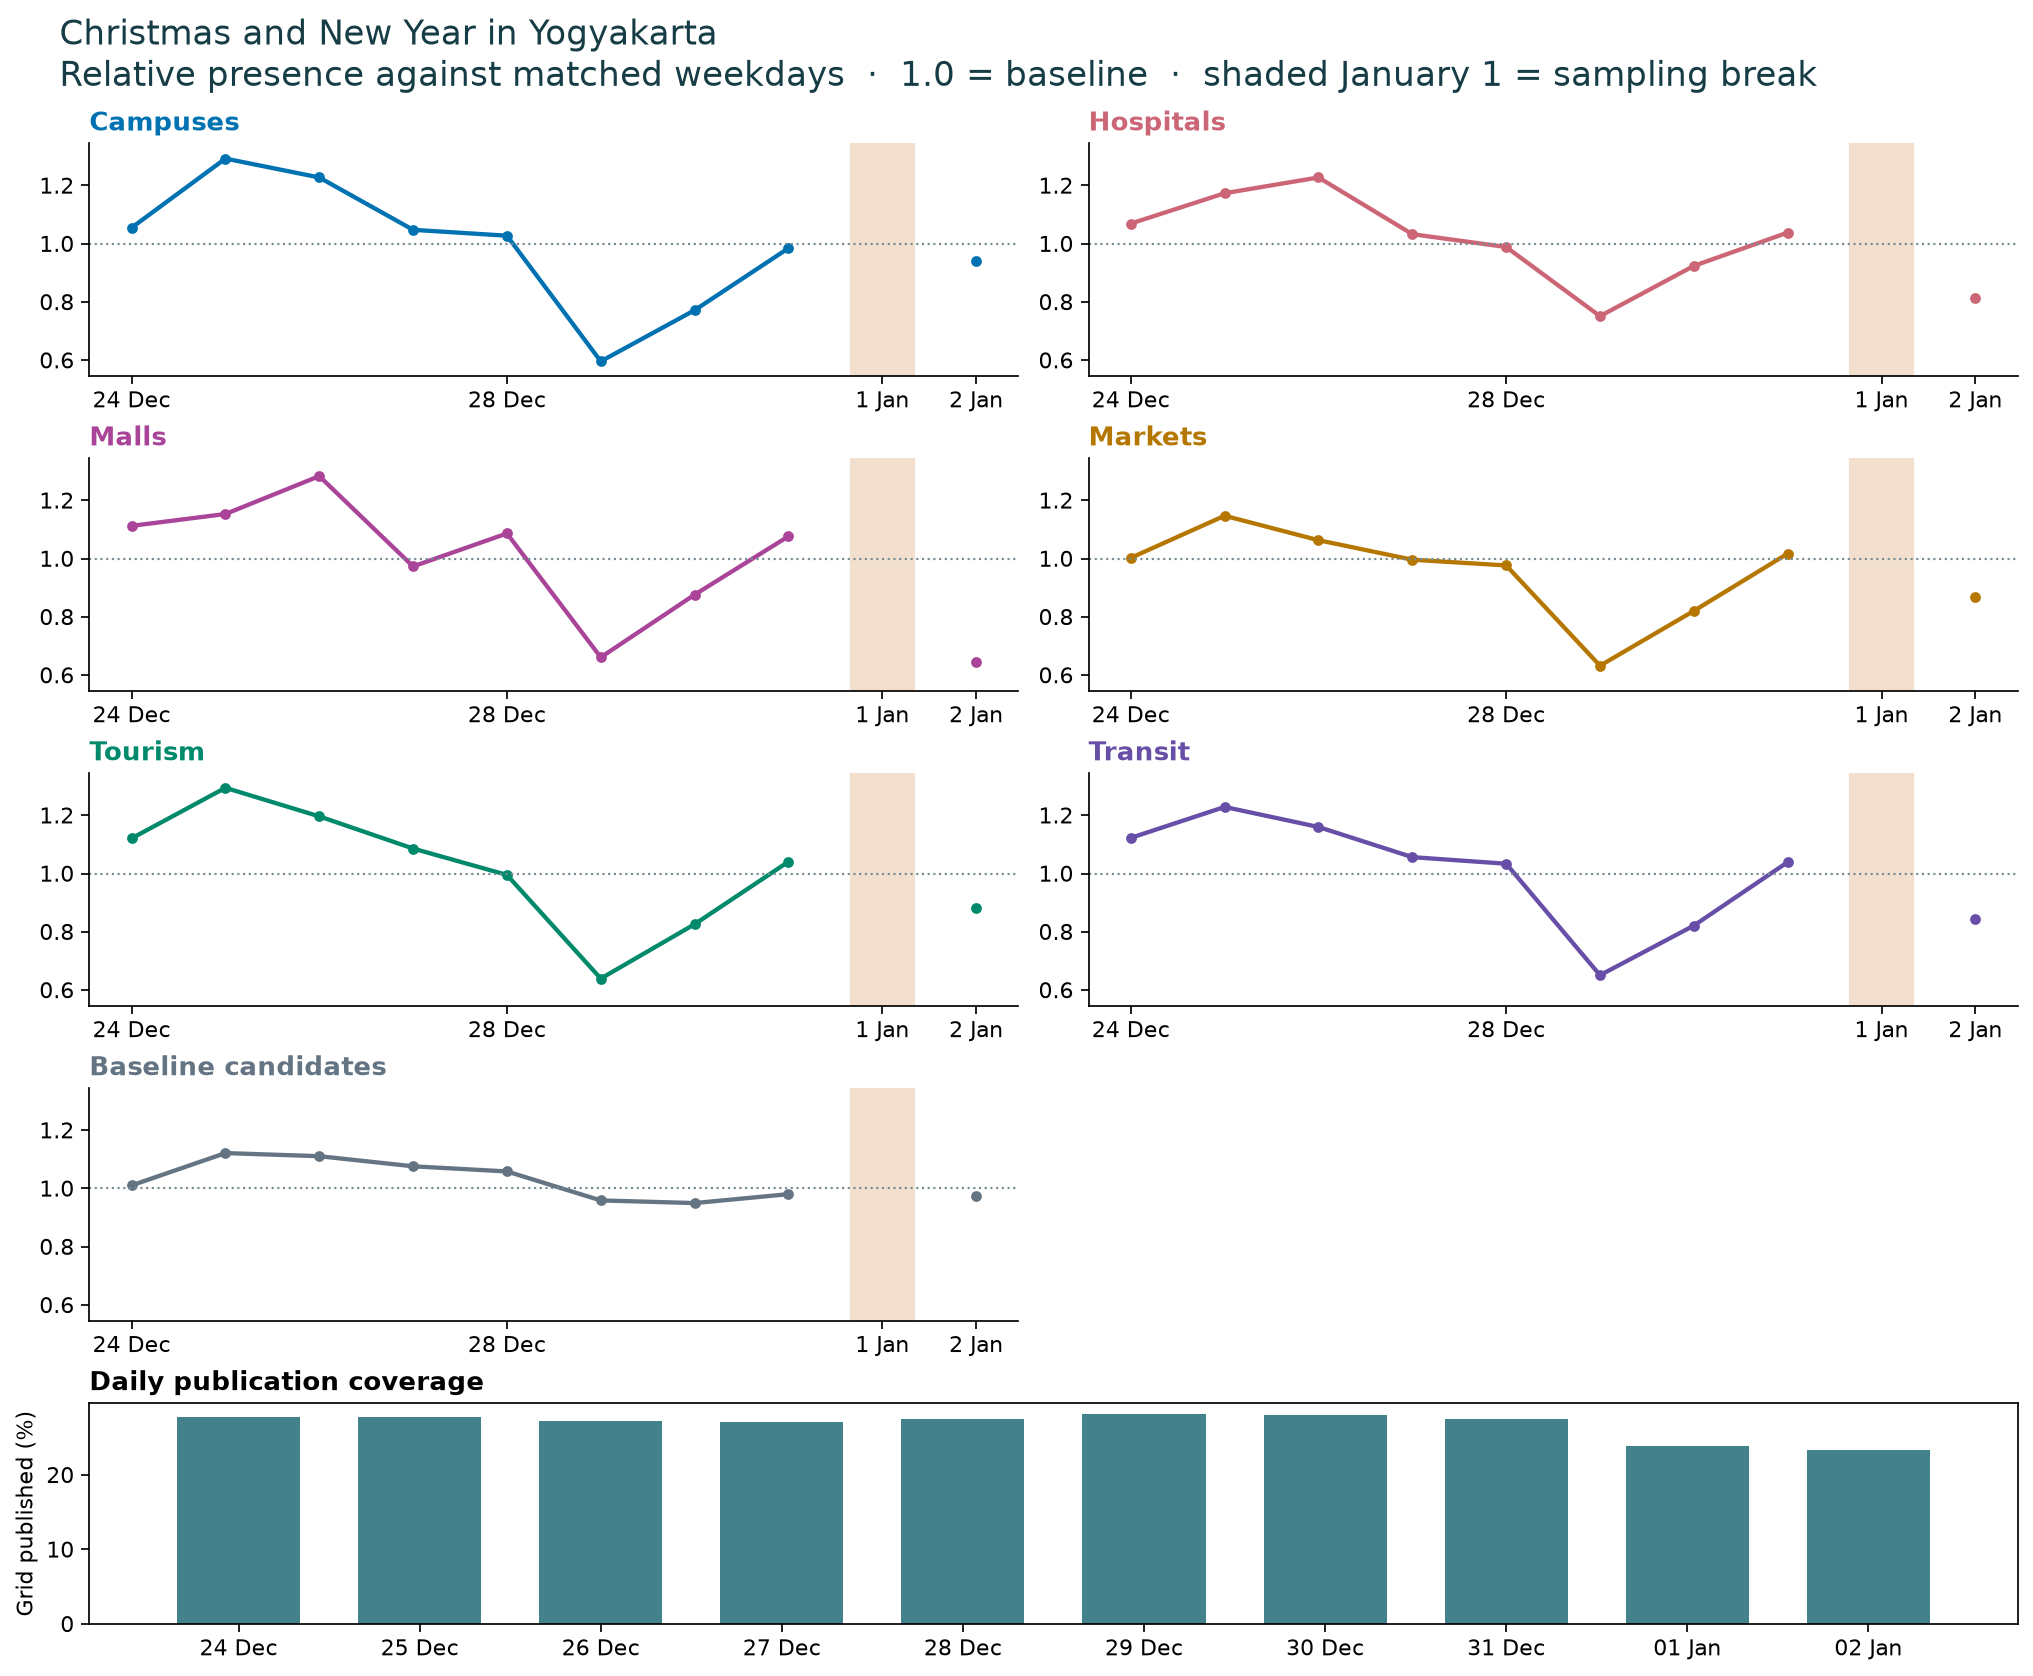

In [4]:
output = Path('nataru_timeseries.png')
holiday(output)
display(Image(filename=str(output)))